# Who's the Real Opponent in 2048? Results

All results for the project, in one place:

1. **All five agents** (Random, Greedy, Minimax, Expectimax, Tuplet) on the same 100 seeded games, in the normal game.
2. **Every agent against every tile spawner**: the villain, normal random tiles, and the helper.
3. **Greedy deep dive**: heuristic ablation and weight sensitivity.
4. **Spawner search depth**: why sabotage is easy and helping takes planning.
5. **Tuplet learning curve**: performance against random tiles and the villain as training grows.

Every figure is saved to `experiments/figures/` for the slides and paper. Cached result CSVs in `experiments/results/` are reused; set `FORCE_RERUN = True` to regenerate (the all-agents run takes about 40 minutes on 8 cores).

Run from the top: **Kernel to Restart & Run All**.

In [1]:
import math
import os
import subprocess
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.lines import Line2D

REPO_ROOT = os.path.abspath("..") if os.path.basename(os.getcwd()) == "experiments" else os.getcwd()
sys.path.insert(0, REPO_ROOT)

from agents.greedy import GreedyAgent
from agents.heuristic import DEFAULT_WEIGHTS, HeuristicWeights
from game import Game, format_board, play_games
from spawners import HelperSpawner, RandomSpawner, VillainSpawner, play_game_with_spawner

FORCE_RERUN = False
RESULTS_DIR = os.path.join(REPO_ROOT, "experiments", "results")
FIG_DIR = os.path.join(REPO_ROOT, "experiments", "figures")
os.makedirs(FIG_DIR, exist_ok=True)


def run_module(*args):
    subprocess.run([sys.executable, "-m", *args], cwd=REPO_ROOT, check=True)

## Chart style

In [2]:
SURFACE = "#ffffff"
INK = "#241c16"        # titles, values
INK_2 = "#3f322a"      # labels, tick text (no light gray text anywhere)
INK_3 = "#5a4636"      # secondary notes
GRID = "#eadfce"
AXIS = "#b9a993"

AGENTS = ["random", "greedy", "minimax", "expectimax", "td"]
AGENT_LABEL = {"random": "Random", "greedy": "Greedy", "minimax": "Minimax", "expectimax": "Expectimax", "td": "Tuplet"}
AGENT_COLOR = {"random": "#6b5d52", "greedy": "#2a78d6", "minimax": "#eb6834", "expectimax": "#199e70", "td": "#6250d6"}
AGENT_MARKER = {"random": "o", "greedy": "s", "minimax": "D", "expectimax": "^", "td": "P"}

SPAWNERS = ["villain", "random", "helper"]
SPAWNER_LABEL = {"villain": "Villain", "random": "Normal game", "helper": "Helper"}
SPAWNER_COLOR = {"villain": "#d63a3a", "random": "#3d3a36", "helper": "#2a78d6"}
WARM_RAMP = ["#fbf3e4", "#f5dfbb", "#f3bd86", "#ec9a64", "#de7650", "#c75a3a", "#a8432f", "#8c3a3f"]

plt.rcParams.update({
    "font.family": ["Avenir Next", "Avenir", "Helvetica Neue", "DejaVu Sans"],
    "font.size": 12.5,
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "figure.dpi": 110, "savefig.dpi": 220,
    "axes.titlesize": 16, "axes.titleweight": "bold", "axes.titlelocation": "left", "axes.titlepad": 26,
    "axes.titlecolor": INK,
    "axes.labelsize": 12.5, "axes.labelcolor": INK_2, "axes.labelweight": "medium",
    "text.color": INK,
    "axes.edgecolor": AXIS, "axes.linewidth": 1.0,
    "xtick.color": AXIS, "ytick.color": AXIS, "xtick.labelcolor": INK_2, "ytick.labelcolor": INK_2,
    "xtick.labelsize": 11.5, "ytick.labelsize": 11.5,
    "axes.spines.top": False, "axes.spines.right": False, "axes.spines.left": False,
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": GRID, "grid.linewidth": 0.9,
    "axes.axisbelow": True, "lines.linewidth": 2.4,
    "legend.frameon": False, "legend.fontsize": 11.5, "legend.labelcolor": INK_2,
})

comma = plt.FuncFormatter(lambda v, _: f"{v:,.0f}")
percent = plt.FuncFormatter(lambda v, _: f"{v:.0f}%")


def subtitle(ax, text):
    """A second line under the title, in readable dark text."""
    ax.text(0, 1.02, text, transform=ax.transAxes, fontsize=11.5, color=INK_3, va="bottom")


def save(fig, name):
    path = os.path.join(FIG_DIR, name)
    fig.savefig(path, bbox_inches="tight")
    print("Saved", os.path.relpath(path, REPO_ROOT))

# 1. All five agents, normal game

Each agent plays seeds 0-99 with normal random tiles. Minimax and Expectimax search 2 moves ahead; the Tuplet uses its 1,000,000-game checkpoint.

In [3]:
ALL_CSV = os.path.join(RESULTS_DIR, "all_agents.csv")
if FORCE_RERUN or not os.path.exists(ALL_CSV):
    run_module("experiments.all_agents", "--games", "100")

runs = pd.read_csv(ALL_CSV)
runs["agent_ms_per_move"] = runs["agent_ms_per_move"].astype(float)
normal = runs[runs.spawner == "random"]

def summarize(df):
    g = df.groupby("agent")
    out = pd.DataFrame({
        "Games": g.size(),
        "Distinct games": g.score.nunique(),
        "Avg score": g.score.mean(),
        "Median score": g.score.median(),
        "Reached 1024 (%)": g.max_tile.apply(lambda t: (t >= 1024).mean() * 100),
        "Reached 2048 (%)": g.max_tile.apply(lambda t: (t >= 2048).mean() * 100),
        "Avg moves": g.moves.mean(),
        "ms per move": g.agent_ms_per_move.mean(),
        "Capped": g.capped.sum(),
    })
    out = out.reindex([a for a in AGENTS if a in out.index])
    out.index = [AGENT_LABEL[a] for a in out.index]
    return out

normal_summary = summarize(normal)
normal_summary.to_csv(os.path.join(RESULTS_DIR, "all_agents_normal_summary.csv"))
normal_summary.style.format({"Avg score": "{:,.0f}", "Median score": "{:,.0f}", "Reached 1024 (%)": "{:.0f}",
                             "Reached 2048 (%)": "{:.0f}", "Avg moves": "{:,.0f}", "ms per move": "{:.2f}"})

,Games,Distinct games,Avg score,Median score,Reached 1024 (%),Reached 2048 (%),Avg moves,ms per move,Capped
Random,100,86,"1,085","1,032",0,0,118,0.04,0
Greedy,100,99,"11,930","11,812",53,12,714,0.16,0
Minimax,100,97,"17,867","16,160",78,34,"1,003",20.70,0
Expectimax,100,99,"32,290","32,934",96,74,"1,663",45.67,0
Tuplet,100,99,"40,585","35,374",94,83,"1,955",0.06,0


## Figure 1: Average score and 2048 rate in the normal game

findfont: Failed to find font weight bold, now using 800.


findfont: Failed to find font weight medium, now using 400.


findfont: Failed to find font weight bold, now using 800.


Saved experiments/figures/fig1_agents_normal.png


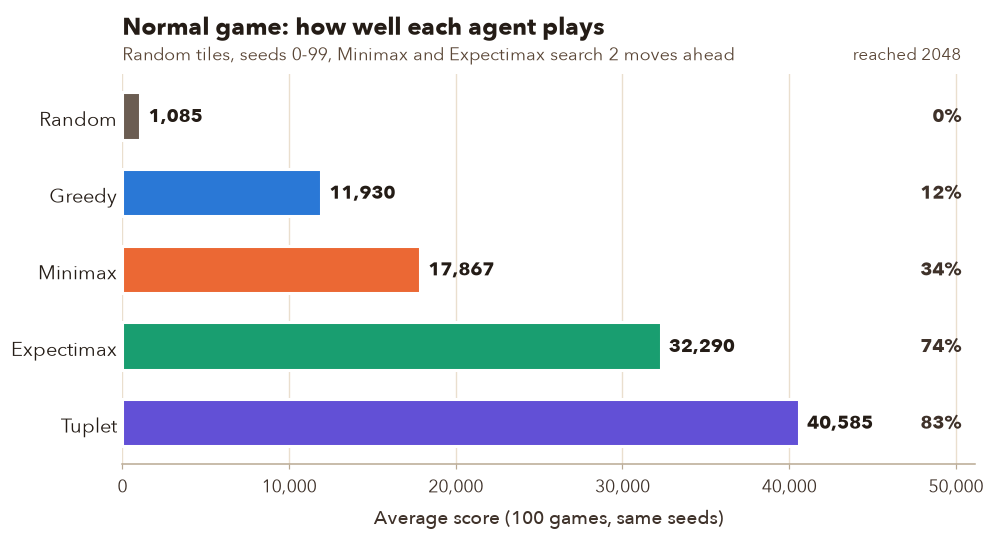

In [4]:
present = [a for a in AGENTS if a in set(normal.agent)]
means = normal.groupby("agent").score.mean()
rate = normal.groupby("agent").max_tile.apply(lambda t: (t >= 2048).mean() * 100)

fig, ax = plt.subplots(figsize=(10, 4.6))
y = np.arange(len(present))[::-1]
ax.barh(y, [means[a] for a in present], color=[AGENT_COLOR[a] for a in present], height=0.62,
        edgecolor=SURFACE, linewidth=2)
for yi, a in zip(y, present):
    ax.text(means[a] + means.max() * 0.012, yi, f"{means[a]:,.0f}", va="center", fontsize=12.5,
            fontweight="bold", color=INK)
    ax.text(means.max() * 1.24, yi, f"{rate[a]:.0f}%", va="center", ha="right", fontsize=12.5,
            fontweight="bold", color=INK_2)
ax.text(means.max() * 1.24, len(present) - 0.35, "reached 2048", ha="right", va="bottom", fontsize=11, color=INK_3)
ax.set_yticks(y, [AGENT_LABEL[a] for a in present], fontsize=13, color=INK)
ax.tick_params(axis="y", length=0)
ax.grid(True, axis="x"); ax.grid(False, axis="y")
ax.set_xlim(0, means.max() * 1.26)
ax.xaxis.set_major_formatter(comma)
ax.set_xlabel("Average score (100 games, same seeds)")
ax.set_title("Normal game: how well each agent plays")
subtitle(ax, "Random tiles, seeds 0-99, Minimax and Expectimax search 2 moves ahead")
save(fig, "fig1_agents_normal.png")
plt.show()

## Figure 2: How far each agent gets

Saved experiments/figures/fig2_agents_tile_reach.png


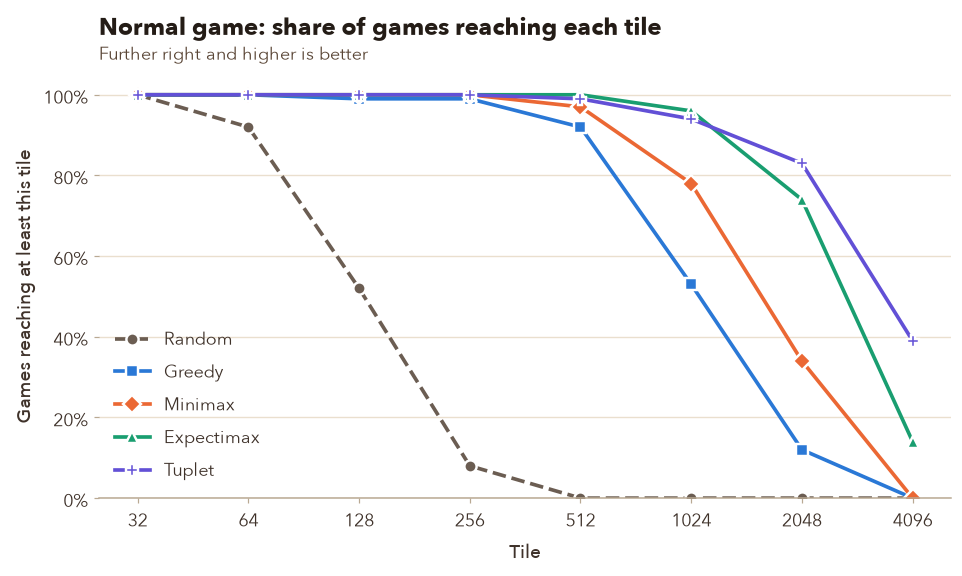

In [5]:
tiles = [2 ** k for k in range(5, 13)]  # 32 ... 4096
x = np.arange(len(tiles))
fig, ax = plt.subplots(figsize=(10, 5))
for a in present:
    sub = normal[normal.agent == a]
    pct = [(sub.max_tile >= t).mean() * 100 for t in tiles]
    ax.plot(x, pct, color=AGENT_COLOR[a], marker=AGENT_MARKER[a], markersize=8, markeredgecolor=SURFACE,
            markeredgewidth=1.6, label=AGENT_LABEL[a], linestyle="--" if a == "random" else "-")
ax.set_xticks(x, [str(t) for t in tiles])
ax.set_ylim(0, 105)
ax.yaxis.set_major_formatter(percent)
ax.set_xlabel("Tile")
ax.set_ylabel("Games reaching at least this tile")
ax.set_title("Normal game: share of games reaching each tile")
subtitle(ax, "Further right and higher is better")
ax.legend(loc="lower left", ncols=1)
save(fig, "fig2_agents_tile_reach.png")
plt.show()

## Figure 3: Is the extra computation worth it?

findfont: Failed to find font weight medium, now using 400.


Saved experiments/figures/fig3_agents_cost.png


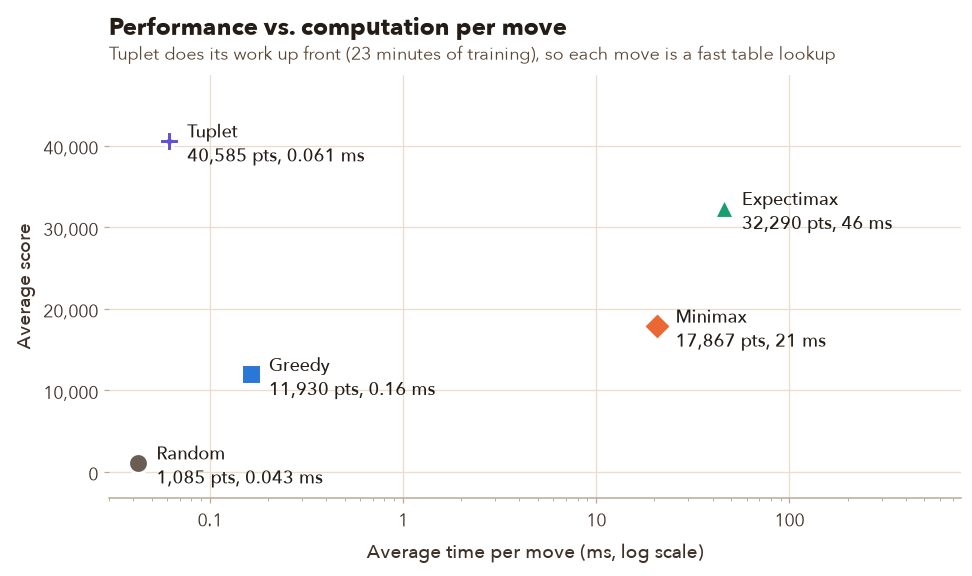

In [6]:
fig, ax = plt.subplots(figsize=(10, 5))
ms = normal.groupby("agent").agent_ms_per_move.mean()
for a in present:
    ax.scatter(ms[a], means[a], s=170, color=AGENT_COLOR[a], marker=AGENT_MARKER[a], edgecolors=SURFACE,
               linewidths=2, zorder=3)
    ax.annotate(f"{AGENT_LABEL[a]}\n{means[a]:,.0f} pts, {ms[a]:.2g} ms", (ms[a], means[a]), xytext=(12, -2),
                textcoords="offset points", va="center", fontsize=11.5, color=INK, fontweight="medium")
ax.set_xscale("log")
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:g}"))
ax.grid(True, axis="both")
ax.set_ylim(-means.max() * 0.08, means.max() * 1.2)
lo, hi = ax.get_xlim(); ax.set_xlim(lo, hi * 12)
ax.yaxis.set_major_formatter(comma)
ax.set_xlabel("Average time per move (ms, log scale)")
ax.set_ylabel("Average score")
ax.set_title("Performance vs. computation per move")
subtitle(ax, "Tuplet does its work up front (23 minutes of training), so each move is a fast table lookup")
save(fig, "fig3_agents_cost.png")
plt.show()

# 2. Every agent vs. every tile spawner

Tiles placed by the full-force **villain** (depth 2), normally at **random**, or by the **helper** (depth 2). The villain and normal-game runs use seeds 0-99. The helper makes games very long, so it uses seeds 0-19 with a 5,000-move cap; capped games are counted in the "Capped" column and make that average an underestimate.

Against the villain or helper the game has no randomness left after the two starting tiles, so deterministic agents produce few distinct games (see "Distinct games"). The Random agent stays random because it picks its own moves randomly.

In [7]:
full = []
for s in SPAWNERS:
    t = summarize(runs[runs.spawner == s])
    t.insert(0, "Spawner", SPAWNER_LABEL[s])
    full.append(t)
full = pd.concat(full)
full.to_csv(os.path.join(RESULTS_DIR, "all_agents_by_spawner_summary.csv"))
full.style.format({"Avg score": "{:,.0f}", "Median score": "{:,.0f}", "Reached 1024 (%)": "{:.0f}",
                   "Reached 2048 (%)": "{:.0f}", "Avg moves": "{:,.0f}", "ms per move": "{:.2f}"})

,Spawner,Games,Distinct games,Avg score,Median score,Reached 1024 (%),Reached 2048 (%),Avg moves,ms per move,Capped
Random,Villain,100,72,344,318,0,0,46,0.05,0
Greedy,Villain,100,10,356,364,0,0,45,0.17,0
Minimax,Villain,100,17,"1,217","1,016",0,0,99,26.72,0
Expectimax,Villain,100,9,791,768,0,0,73,46.61,0
Tuplet,Villain,100,16,686,588,0,0,68,0.03,0
Random,Normal game,100,86,"1,085","1,032",0,0,118,0.04,0
Greedy,Normal game,100,99,"11,930","11,812",53,12,714,0.16,0
Minimax,Normal game,100,97,"17,867","16,160",78,34,"1,003",20.70,0
Expectimax,Normal game,100,99,"32,290","32,934",96,74,"1,663",45.67,0
Tuplet,Normal game,100,99,"40,585","35,374",94,83,"1,955",0.06,0


## Figure 4: The same agents, three different opponents

findfont: Failed to find font weight bold, now using 800.


Saved experiments/figures/fig4_agents_vs_spawners.png


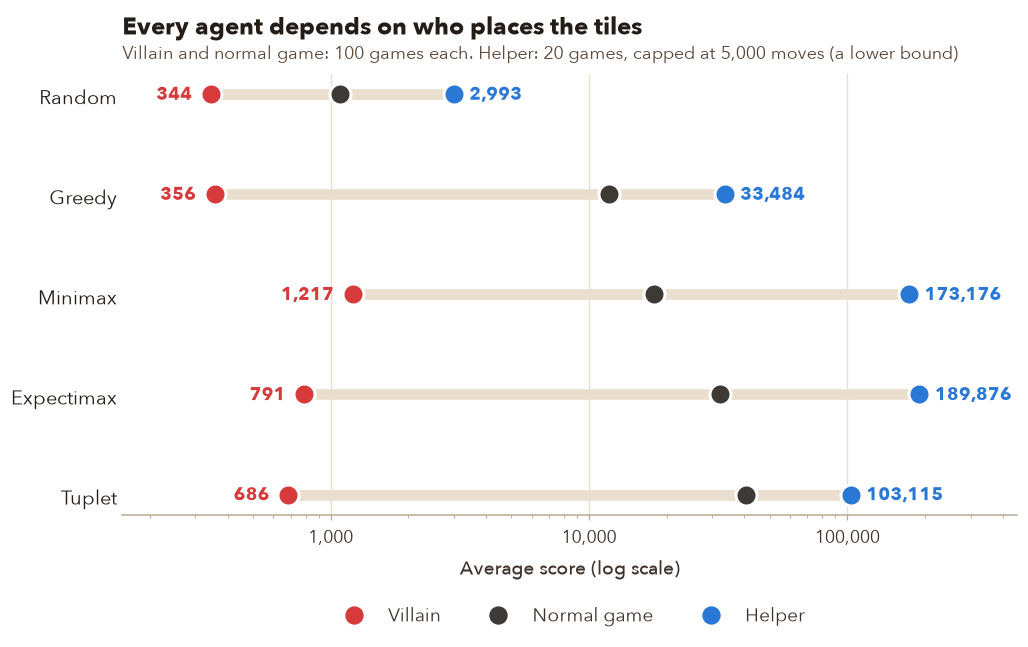

In [8]:
avg = runs.groupby(["agent", "spawner"]).score.mean().unstack()
fig, ax = plt.subplots(figsize=(10.5, 5.2))
y = np.arange(len(present))[::-1]
for yi, a in zip(y, present):
    vals = [avg.loc[a, s] for s in SPAWNERS if s in avg.columns]
    ax.plot([min(vals), max(vals)], [yi, yi], color=GRID, linewidth=7, solid_capstyle="round", zorder=1)
    for s in SPAWNERS:
        if s in avg.columns:
            ax.scatter(avg.loc[a, s], yi, s=190, color=SPAWNER_COLOR[s], edgecolors=SURFACE, linewidths=2, zorder=3)
    ax.text(avg.loc[a, "villain"] / 1.18, yi, f"{avg.loc[a, 'villain']:,.0f}", ha="right", va="center",
            fontsize=11.5, color=SPAWNER_COLOR["villain"], fontweight="bold")
    ax.text(avg.loc[a, "helper"] * 1.15, yi, f"{avg.loc[a, 'helper']:,.0f}", ha="left", va="center",
            fontsize=11.5, color=SPAWNER_COLOR["helper"], fontweight="bold")
ax.set_xscale("log")
ax.xaxis.set_major_formatter(comma)
ax.set_yticks(y, [AGENT_LABEL[a] for a in present], fontsize=13, color=INK)
ax.tick_params(axis="y", length=0)
ax.grid(True, axis="x"); ax.grid(False, axis="y")
lo = avg.values.min() / 2.2; hi = avg.values.max() * 2.4
ax.set_xlim(lo, hi)
ax.set_xlabel("Average score (log scale)")
ax.set_title("Every agent depends on who places the tiles")
subtitle(ax, "Villain and normal game: 100 games each. Helper: 20 games, capped at 5,000 moves (a lower bound)")
handles = [Line2D([], [], marker="o", linestyle="", markersize=11, color=SPAWNER_COLOR[s], label=SPAWNER_LABEL[s])
           for s in SPAWNERS]
ax.legend(handles=handles, loc="upper center", bbox_to_anchor=(0.5, -0.16), ncols=3, fontsize=12.5)
save(fig, "fig4_agents_vs_spawners.png")
plt.show()

## Figure 5: Surviving the villain

Saved experiments/figures/fig5_villain_survival.png


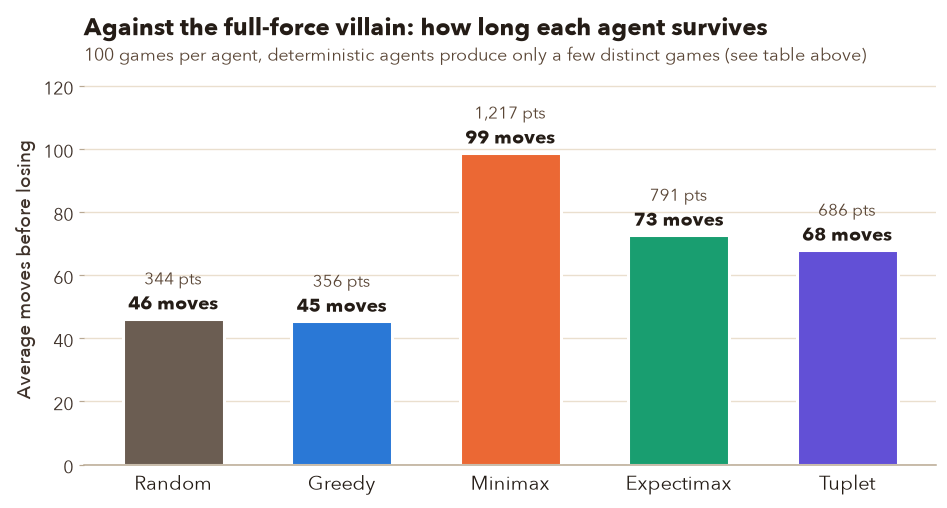

In [9]:
vil = runs[runs.spawner == "villain"]
surv = vil.groupby("agent").moves.mean().reindex(present)
vscore = vil.groupby("agent").score.mean().reindex(present)
fig, ax = plt.subplots(figsize=(10, 4.6))
x = np.arange(len(present))
ax.bar(x, surv.values, color=[AGENT_COLOR[a] for a in present], width=0.6, edgecolor=SURFACE, linewidth=2)
for xi, a in zip(x, present):
    ax.text(xi, surv[a] + surv.max() * 0.03, f"{surv[a]:.0f} moves", ha="center", fontsize=12.5,
            fontweight="bold", color=INK)
    ax.text(xi, surv[a] + surv.max() * 0.11, f"{vscore[a]:,.0f} pts", ha="center", fontsize=11, color=INK_3)
ax.set_xticks(x, [AGENT_LABEL[a] for a in present], fontsize=13, color=INK)
ax.tick_params(axis="x", length=0)
ax.set_ylim(0, surv.max() * 1.25)
ax.set_ylabel("Average moves before losing")
ax.set_title("Against the full-force villain: how long each agent survives")
subtitle(ax, "100 games per agent, deterministic agents produce only a few distinct games (see table above)")
save(fig, "fig5_villain_survival.png")
plt.show()

# 3. Greedy deep dive

The Greedy agent's shared heuristic (empty cells, monotonicity, smoothness, corner) is also what Minimax and Expectimax use. Weights were tuned on seeds 1000-1059 and checked on held-out seeds 5000-5099.

Saved experiments/figures/fig6_greedy_ablation.png


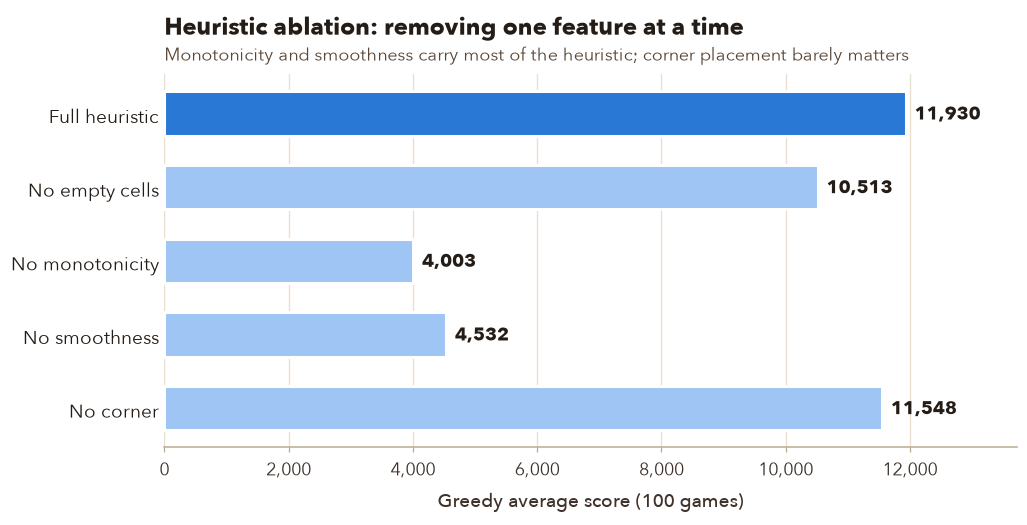

In [10]:
full_w = DEFAULT_WEIGHTS
variants = {
    "Full heuristic": full_w,
    "No empty cells": HeuristicWeights(0, full_w.monotonicity, full_w.smoothness, full_w.corner),
    "No monotonicity": HeuristicWeights(full_w.empty, 0, full_w.smoothness, full_w.corner),
    "No smoothness": HeuristicWeights(full_w.empty, full_w.monotonicity, 0, full_w.corner),
    "No corner": HeuristicWeights(full_w.empty, full_w.monotonicity, full_w.smoothness, 0),
}
ABL_CSV = os.path.join(RESULTS_DIR, "greedy_ablation.csv")
if FORCE_RERUN or not os.path.exists(ABL_CSV):
    rows = []
    for name, w in variants.items():
        res = play_games(GreedyAgent(w), list(range(100)))
        rows.append({"variant": name, "avg_score": np.mean([r.score for r in res]),
                     "reached_1024_pct": np.mean([r.max_tile >= 1024 for r in res]) * 100,
                     "reached_2048_pct": np.mean([r.max_tile >= 2048 for r in res]) * 100})
    pd.DataFrame(rows).to_csv(ABL_CSV, index=False)
ablation = pd.read_csv(ABL_CSV)

fig, ax = plt.subplots(figsize=(10, 4.4))
y = np.arange(len(ablation))[::-1]
cols = [AGENT_COLOR["greedy"] if v == "Full heuristic" else "#9ec5f4" for v in ablation.variant]
ax.barh(y, ablation.avg_score, color=cols, height=0.6, edgecolor=SURFACE, linewidth=2)
for yi, s in zip(y, ablation.avg_score):
    ax.text(s + ablation.avg_score.max() * 0.012, yi, f"{s:,.0f}", va="center", fontsize=12.5, fontweight="bold", color=INK)
ax.set_yticks(y, ablation.variant, fontsize=12.5, color=INK)
ax.tick_params(axis="y", length=0)
ax.grid(True, axis="x"); ax.grid(False, axis="y")
ax.xaxis.set_major_formatter(comma)
ax.set_xlim(0, ablation.avg_score.max() * 1.15)
ax.set_xlabel("Greedy average score (100 games)")
ax.set_title("Heuristic ablation: removing one feature at a time")
subtitle(ax, "Monotonicity and smoothness carry most of the heuristic; corner placement barely matters")
save(fig, "fig6_greedy_ablation.png")
plt.show()

findfont: Failed to find font weight bold, now using 800.


Saved experiments/figures/fig7_greedy_weight_sensitivity.png


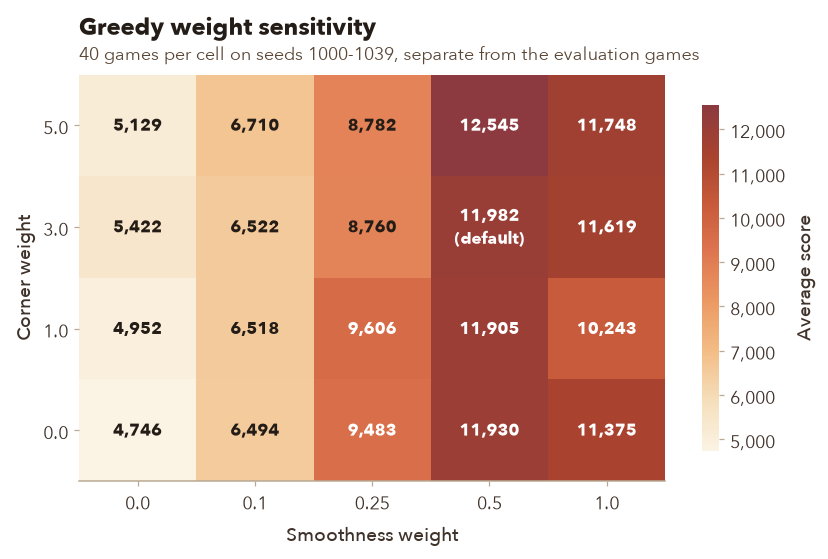

In [11]:
SWEEP_SEEDS = list(range(1000, 1040))
smooth_values = [0.0, 0.1, 0.25, 0.5, 1.0]
corner_values = [0.0, 1.0, 3.0, 5.0]
SWEEP_CSV = os.path.join(RESULTS_DIR, "greedy_weight_sweep.csv")
if FORCE_RERUN or not os.path.exists(SWEEP_CSV):
    rows = []
    for c in corner_values:
        for s in smooth_values:
            w = HeuristicWeights(full_w.empty, full_w.monotonicity, s, c)
            rows.append({"corner": c, "smoothness": s,
                         "avg_score": np.mean([r.score for r in play_games(GreedyAgent(w), SWEEP_SEEDS)])})
    pd.DataFrame(rows).to_csv(SWEEP_CSV, index=False)
sweep = pd.read_csv(SWEEP_CSV)
grid = sweep.pivot(index="corner", columns="smoothness", values="avg_score").loc[corner_values, smooth_values].values

cmap = LinearSegmentedColormap.from_list("warm", WARM_RAMP)
fig, ax = plt.subplots(figsize=(8.6, 4.8))
im = ax.imshow(grid, cmap=cmap, aspect="auto", origin="lower")
ax.grid(False)
ax.set_xticks(range(len(smooth_values)), [str(v) for v in smooth_values])
ax.set_yticks(range(len(corner_values)), [str(v) for v in corner_values])
ax.set_xlabel("Smoothness weight"); ax.set_ylabel("Corner weight")
thr = grid.min() + 0.55 * (grid.max() - grid.min())
for i in range(len(corner_values)):
    for j in range(len(smooth_values)):
        default = corner_values[i] == full_w.corner and smooth_values[j] == full_w.smoothness
        ax.text(j, i, f"{grid[i, j]:,.0f}" + ("\n(default)" if default else ""), ha="center", va="center",
                fontsize=11, fontweight="bold", color="#ffffff" if grid[i, j] > thr else INK)
cbar = fig.colorbar(im, ax=ax, shrink=0.85)
cbar.outline.set_visible(False)
cbar.ax.yaxis.set_major_formatter(comma)
cbar.ax.tick_params(colors=AXIS, labelcolor=INK_2)
cbar.set_label("Average score", color=INK_2)
ax.set_title("Greedy weight sensitivity")
subtitle(ax, "40 games per cell on seeds 1000-1039, separate from the evaluation games")
save(fig, "fig7_greedy_weight_sensitivity.png")
plt.show()

# 4. Spawner search depth (Greedy)

How far ahead the spawner looks matters very differently for sabotage and for help.

Saved experiments/figures/fig8_spawner_depth.png


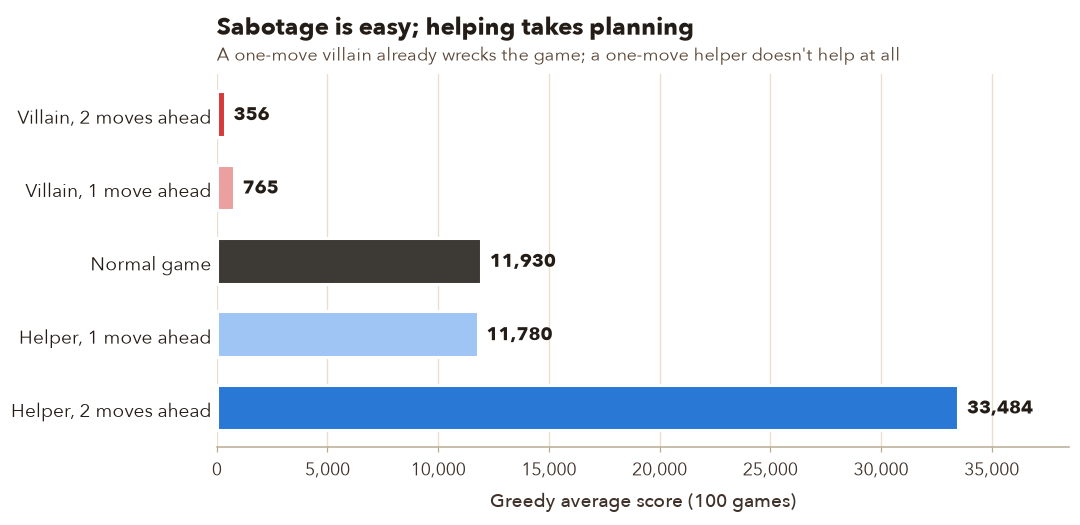

In [12]:
sp = pd.read_csv(os.path.join(RESULTS_DIR, "greedy_vs_spawners.csv"))
order = [("villain", 2), ("villain", 1), ("random", 0), ("helper", 1), ("helper", 2)]
labels = {("villain", 2): "Villain, 2 moves ahead", ("villain", 1): "Villain, 1 move ahead",
          ("random", 0): "Normal game", ("helper", 1): "Helper, 1 move ahead", ("helper", 2): "Helper, 2 moves ahead"}
colors = {("villain", 2): "#d63a3a", ("villain", 1): "#ec9f9f", ("random", 0): "#3d3a36",
          ("helper", 1): "#9ec5f4", ("helper", 2): "#2a78d6"}
vals = [sp[(sp.spawner == s) & (sp.depth == d)].score.mean() for s, d in order]

fig, ax = plt.subplots(figsize=(10, 4.4))
y = np.arange(len(order))[::-1]
ax.barh(y, vals, color=[colors[k] for k in order], height=0.62, edgecolor=SURFACE, linewidth=2)
for yi, v in zip(y, vals):
    ax.text(v + max(vals) * 0.012, yi, f"{v:,.0f}", va="center", fontsize=12.5, fontweight="bold", color=INK)
ax.set_yticks(y, [labels[k] for k in order], fontsize=12.5, color=INK)
ax.tick_params(axis="y", length=0)
ax.grid(True, axis="x"); ax.grid(False, axis="y")
ax.xaxis.set_major_formatter(comma)
ax.set_xlim(0, max(vals) * 1.15)
ax.set_xlabel("Greedy average score (100 games)")
ax.set_title("Sabotage is easy; helping takes planning")
subtitle(ax, "A one-move villain already wrecks the game; a one-move helper doesn't help at all")
save(fig, "fig8_spawner_depth.png")
plt.show()

findfont: Failed to find font weight bold, now using 800.


findfont: Failed to find font weight bold, now using 800.


findfont: Failed to find font weight bold, now using 800.


Saved experiments/figures/fig9_spawner_final_boards.png


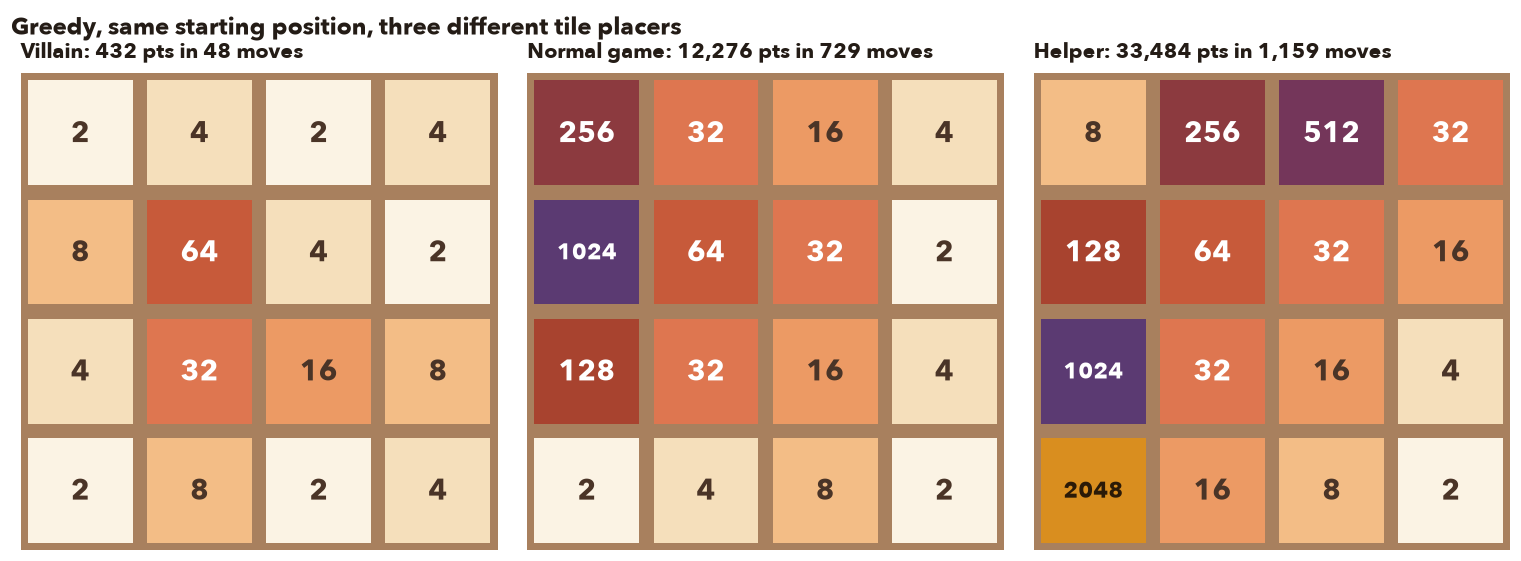

In [13]:
def draw_board(ax, board, title):
    cols = {2: "#fbf3e4", 4: "#f5dfbb", 8: "#f3bd86", 16: "#ec9a64", 32: "#de7650", 64: "#c75a3a", 128: "#a8432f",
            256: "#8c3a3f", 512: "#74365a", 1024: "#5b3a72", 2048: "#d98e1f", 4096: "#2f2a3a"}
    ax.add_patch(plt.Rectangle((0, 0), 4, 4, facecolor="#a8805e", edgecolor="none"))
    for r in range(4):
        for c in range(4):
            v = board[r][c]
            ax.add_patch(plt.Rectangle((c + 0.06, 3 - r + 0.06), 0.88, 0.88,
                                       facecolor=cols.get(v, "#c9a985") if v else "#c9a985", edgecolor="none"))
            if v:
                ax.text(c + 0.5, 3 - r + 0.5, str(v), ha="center", va="center", fontweight="bold",
                        fontsize=19 if v < 1000 else 15, color="#4a3427" if v <= 16 else ("#2b1a07" if v == 2048 else "#fff"))
    ax.set_xlim(0, 4); ax.set_ylim(0, 4); ax.set_aspect("equal"); ax.axis("off")
    ax.set_title(title, fontsize=13.5, pad=10)

matchups = [("Villain", VillainSpawner(depth=2)), ("Normal game", RandomSpawner()), ("Helper", HelperSpawner(depth=2))]
fig, axes = plt.subplots(1, 3, figsize=(14, 5.2))
for ax, (name, spawner) in zip(axes, matchups):
    r = play_game_with_spawner(GreedyAgent(), spawner, seed=0, max_moves=20000)
    draw_board(ax, r.final_board, f"{name}: {r.score:,} pts in {r.moves:,} moves")
fig.suptitle("Greedy, same starting position, three different tile placers", x=0.01, ha="left",
             fontsize=16, fontweight="bold", color=INK)
fig.tight_layout()
save(fig, "fig9_spawner_final_boards.png")
plt.show()

# 5. Tuplet: learning curve

Tuplet learns from self-play with temporal-difference learning on an n-tuple network (Szubert & Jaskowski, 2014; implemented from scratch in `td/`). It trains only on normal random tiles. Each checkpoint plays the same 100 games with random tiles and against the full-force villain.

findfont: Failed to find font weight bold, now using 800.


Saved experiments/figures/fig10_td_training_curve.png


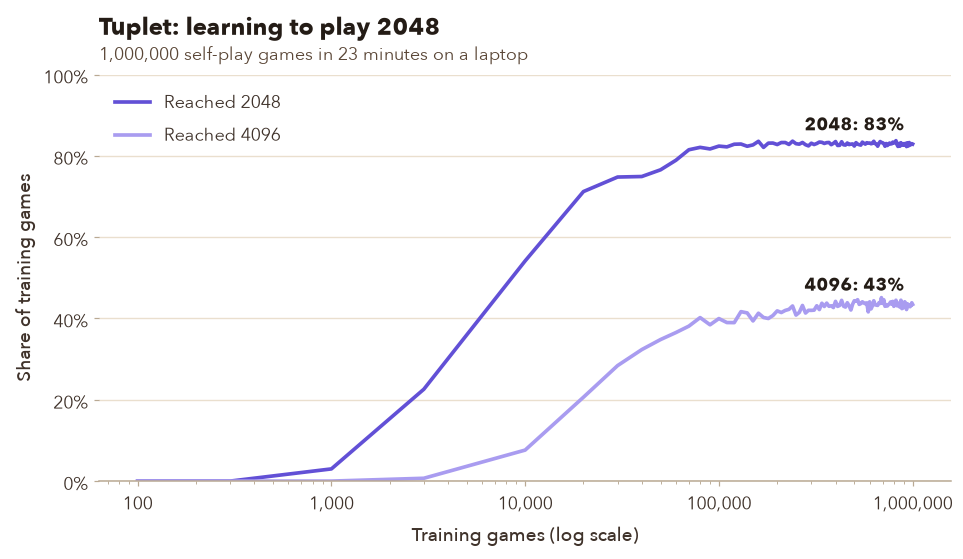

In [14]:
TD_CSV = os.path.join(RESULTS_DIR, "td_learning_curve.csv")
if FORCE_RERUN or not os.path.exists(TD_CSV):
    run_module("experiments.td_learning_curve", "--games", "100")
train_log = pd.read_csv(os.path.join(REPO_ROOT, "td", "checkpoints", "training_log.csv"))
td = pd.read_csv(TD_CSV)
td_summary = td.groupby(["spawner", "games_trained"]).agg(
    avg_score=("score", "mean"), reached_2048=("max_tile", lambda t: (t >= 2048).mean() * 100),
    avg_moves=("moves", "mean"), distinct_games=("score", "nunique")).reset_index()
td_summary.to_csv(os.path.join(RESULTS_DIR, "td_learning_curve_summary.csv"), index=False)

fig, ax = plt.subplots(figsize=(10, 4.8))
ax.plot(train_log.games, train_log.rate_2048 * 100, color=AGENT_COLOR["td"], label="Reached 2048")
ax.plot(train_log.games, train_log.rate_4096 * 100, color="#a99cf0", label="Reached 4096")
ax.set_xscale("log"); ax.xaxis.set_major_formatter(comma)
ax.set_ylim(0, 100); ax.yaxis.set_major_formatter(percent)
last = train_log.iloc[-1]
for col, lab in [("rate_2048", "2048"), ("rate_4096", "4096")]:
    ax.annotate(f"{lab}: {last[col] * 100:.0f}%", (last.games, last[col] * 100), xytext=(-6, 9),
                textcoords="offset points", ha="right", fontsize=12, fontweight="bold", color=INK)
ax.set_xlabel("Training games (log scale)"); ax.set_ylabel("Share of training games")
ax.set_title("Tuplet: learning to play 2048")
subtitle(ax, f"{int(last.games):,} self-play games in {last.elapsed_s / 60:.0f} minutes on a laptop")
ax.legend(loc="upper left")
save(fig, "fig10_td_training_curve.png")
plt.show()

Saved experiments/figures/fig11_td_vs_villain_curve.png


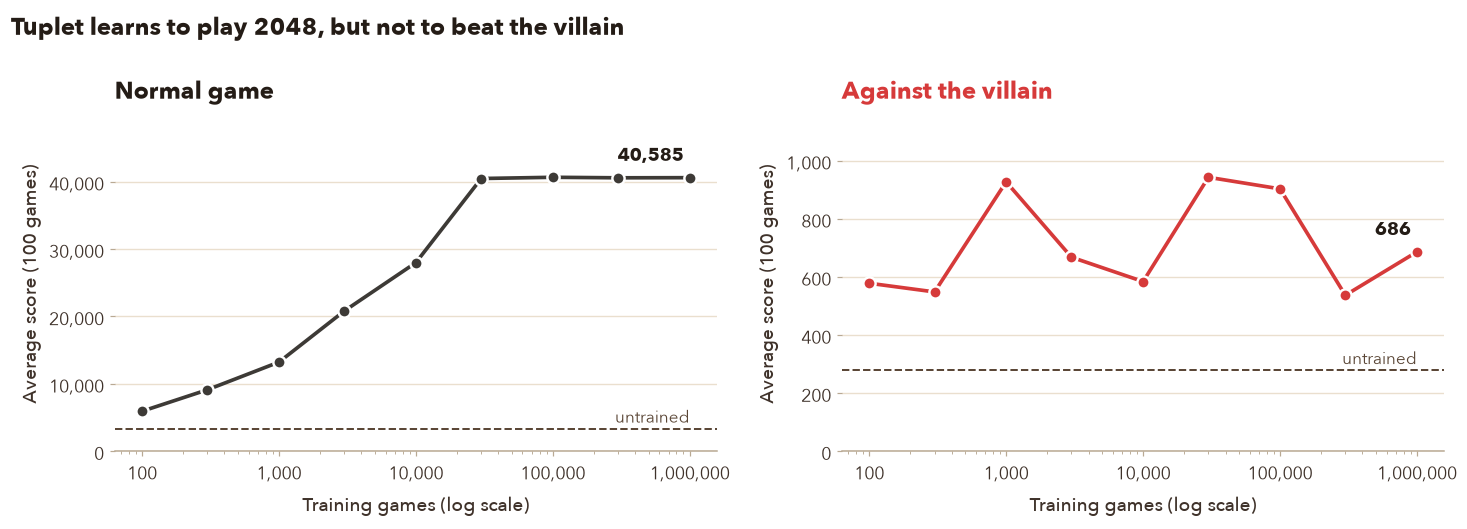

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.9))
for ax, (s, col, title) in zip(axes, [("random", SPAWNER_COLOR["random"], "Normal game"),
                                      ("villain", SPAWNER_COLOR["villain"], "Against the villain")]):
    sub = td_summary[(td_summary.spawner == s) & (td_summary.games_trained > 0)]
    ax.plot(sub.games_trained, sub.avg_score, color=col, marker="o", markersize=8, markeredgecolor=SURFACE,
            markeredgewidth=1.6)
    base = td_summary[(td_summary.spawner == s) & (td_summary.games_trained == 0)].avg_score.iloc[0]
    ax.axhline(base, color=INK_3, linewidth=1.3, linestyle="--")
    ax.text(sub.games_trained.max(), base, "untrained", ha="right", va="bottom", fontsize=11, color=INK_3)
    lastrow = sub.iloc[-1]
    ax.annotate(f"{lastrow.avg_score:,.0f}", (lastrow.games_trained, lastrow.avg_score), xytext=(-4, 11),
                textcoords="offset points", ha="right", fontsize=12.5, fontweight="bold", color=INK)
    ax.set_xscale("log"); ax.xaxis.set_major_formatter(comma); ax.yaxis.set_major_formatter(comma)
    ax.set_ylim(0, sub.avg_score.max() * 1.22)
    ax.set_xlabel("Training games (log scale)"); ax.set_ylabel("Average score (100 games)")
    ax.set_title(title, color=col if s == "villain" else INK, pad=12)
fig.suptitle("Tuplet learns to play 2048, but not to beat the villain", x=0.01, ha="left",
             fontsize=16, fontweight="bold", color=INK)
fig.tight_layout()
save(fig, "fig11_td_vs_villain_curve.png")
plt.show()

# Notes for the paper

- **Same games everywhere:** all agent comparisons use seeds 0-99. Greedy's weights were tuned on seeds 1000-1059 and checked on 5000-5099. The Minimax branch's own depth and weight experiments (seeds 2000-3099) are in `experiments/minimax.ipynb`, and the Random baseline's original analysis is in `experiments/results/random_baseline.ipynb`.
- **Search depth:** Minimax and Expectimax search 2 player moves ahead (their defaults). The villain and helper also search 2 moves ahead and model the player with the shared heuristic, so against Greedy they know their opponent exactly; against the other agents they use a proxy.
- **Sample size against the villain and helper:** after the two starting tiles these games are deterministic for every agent except Random, so report the "Distinct games" column alongside averages.
- **Spawner power:** the villain and helper choose the tile value (2 or 4) as well as its position.
- **Timing** depends on the machine; scores are deterministic for a given seed.